# Super-Resolution Pipeline for Turbulence Data (Physics-Informed)

End-to-end notebook for training and evaluating physics-informed super-resolution models on turbulence data from JHTDB.

**Pipeline overview:**
1. Load configuration (YAML) and setup experiment workspace
2. Load velocity and vorticity fields from HDF5 (ux, uy, omega_z)
3. Create snapshot-wise splits (NO temporal leakage!)
4. Build datasets with automatic LR creation (via average pooling)
5. **NEW: Train model with physics-informed losses (advection + diffusion)**
6. Evaluate on full test snapshots with baseline comparisons
7. Save trained model with metadata

**Key features:**
- **Physics-informed training**: Advection and viscous diffusion losses from vorticity transport equation
- **Snapshot-wise splits**: No temporal leakage, proper generalization
- **Automatic LR creation**: Average pooling (scale=4) from HR
- **Temporal stacking (MTPC)**: Optional N-frame temporal context
- **Physics-aware augmentations**: Cyclic shifts, flips with sign maps, 180° rotation
- **Configuration-driven**: All settings in YAML files
- **Model factory pattern**: Easy architecture swapping (unet, unet_turb, mlp)
- **Comprehensive evaluation**: PSNR, energy spectra, enstrophy, correlations

**Physics losses:**
- **Advection**: Penalizes u·∇ω (vorticity transport by flow)
- **Diffusion**: Penalizes ∇²ω (viscous smoothing)
- Based on vorticity transport: ∂ω/∂t + u·∇ω = ν∇²ω

**Training pairs**: 64×64 LR input → 256×256 HR target (4× super-resolution)

## Setup and Imports

In [1]:
import sys
sys.path.append('..')

from pathlib import Path
from datetime import datetime
from contextlib import nullcontext
import json
import warnings

import h5py
import yaml
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

from models.factory import build_model_from_config, available_models
from utils.experiment_manager import ExperimentManager
from utils.losses import GradientLoss, SpectralLoss
from utils.physics_losses import PhysicsInformedLoss, compute_vorticity_from_velocity
from utils.metrics import psnr
from utils.sr_datasets import (
    TemporalStackDataset, 
    MultiFieldDataset,
    create_snapshot_splits, 
    compute_global_stats,
    compute_multifield_stats
)

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['figure.facecolor'] = 'white'

print("✓ Libraries loaded successfully")
print(f"  PyTorch version: {torch.__version__}")
print(f"  Device available: {'MPS' if torch.backends.mps.is_available() else 'CUDA' if torch.cuda.is_available() else 'CPU'}")
print(f"  Available models: {available_models()}")

✓ Libraries loaded successfully
  PyTorch version: 2.9.0
  Device available: MPS
  Available models: ('edsr', 'hdsc_ms', 'mlp', 'unet')


## Configuration and Experiment Setup

Load YAML configuration and initialize experiment workspace.

In [2]:
# Locate project root and config file
ROOT = Path.cwd()
if not (ROOT / 'configs').exists():
    ROOT = ROOT.parent

# Choose configuration file
# OPTIONS:
#   - 'configs/sr_unet.yaml': Baseline U-Net (no physics)
#   - 'configs/sr_hdsc_ms.yaml': Hybrid DSC/MS (no physics)
#   - 'configs/sr_hdsc_ms_physics.yaml': Hybrid DSC/MS with physics-informed losses
#   - 'configs/sr_mlp.yaml': MLP baseline (no physics)

CONFIG_PATH = ROOT / 'configs/sr_edsr.yaml'  # ← Change this line to switch configs

# Load configuration
with open(CONFIG_PATH) as fp:
    config = yaml.safe_load(fp)

print("Configuration loaded:")
print(json.dumps({
    "experiment": config['experiment']['name'],
    "model": config['model']['architecture'],
    "component": config['data']['component'],
    "scale": config['model']['scale_factor'],
    "epochs": config['training']['epochs'],
    "batch_size": config['training']['batch_size'],
    "temporal_stacking": config['data']['temporal']['enabled'],
    "augmentation": config['data']['augmentation']['enabled'],
    "physics_enabled": config['loss']['components'].get('physics', {}).get('enabled', False)
}, indent=2))

# Setup experiment workspace
exp_cfg = config['experiment']
manager = ExperimentManager(task='SR', name=exp_cfg['name'], base_dir=ROOT / 'work')
manager.setup()
manager.save_config(config)

FIGURES_DIR = manager.plots_dir
print(f"\nWorking directory: {manager.run_dir}")
print(f"  Checkpoints: {manager.checkpoints_dir}")
print(f"  Predictions: {manager.predictions_dir}")
print(f"  Plots: {manager.plots_dir}")

Configuration loaded:
{
  "experiment": "sr_edsr_isotropic",
  "model": "edsr",
  "component": "omega_z",
  "scale": 4,
  "epochs": 100,
  "batch_size": 16,
  "temporal_stacking": false,
  "augmentation": false,
  "physics_enabled": false
}

Working directory: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/work/SR/sr_edsr_isotropic_20251108_220719
  Checkpoints: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/work/SR/sr_edsr_isotropic_20251108_220719/checkpoints
  Predictions: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/work/SR/sr_edsr_isotropic_20251108_220719/predictions
  Plots: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/work/SR/sr_edsr_isotropic_20251108_220719/plots


## Data Loading

Load velocity and vorticity snapshots from HDF5. For physics-informed training, we need:
- **ux, uy**: Velocity components (for advection term u·∇ω)
- **omega_z**: Vorticity (target field for SR)

In [3]:
# Load dataset
h5_path = (ROOT / config['data']['h5_path']).resolve()
print(f"Loading data from: {h5_path}")

fields = {}
times = []
y_values = []

with h5py.File(h5_path, 'r') as h5:
    # Check structure
    top_keys = list(h5.keys())
    print(f"Top-level keys: {top_keys}")
    
    if 'snapshots' in h5:
        # Hierarchical structure
        snapshots = h5['snapshots']
        snap_keys = sorted(snapshots.keys())
        print(f"Found {len(snap_keys)} snapshots")
        
        for key in snap_keys:
            snap = snapshots[key]
            for field_name in ['ux', 'uy', 'uz', 'omega_z']:
                if field_name in snap:
                    fields.setdefault(field_name, []).append(np.asarray(snap[field_name]))
            if 'time' in snap:
                times.append(float(np.asarray(snap['time'])))
            if 'y_value' in snap:
                y_values.append(np.asarray(snap['y_value']))
    else:
        # Flat structure
        for field_name in ['ux', 'uy', 'uz', 'omega_z']:
            if field_name in h5:
                fields[field_name] = [np.asarray(h5[field_name])]
        if 'time' in h5:
            times.append(np.asarray(h5['time']))
        if 'y_value' in h5:
            y_values.append(np.asarray(h5['y_value']))

# Verify required fields
required = ['ux', 'uy', 'omega_z']
missing = [name for name in required if name not in fields]
if missing:
    raise KeyError(f"Missing required fields: {missing}. Available: {list(fields.keys())}")

# Stack into arrays
ux = np.stack(fields['ux'])
uy = np.stack(fields['uy'])
omega = np.stack(fields['omega_z'])
times = np.asarray(times) if times else np.arange(ux.shape[0])
y_values = np.asarray(y_values) if y_values else None

print(f"\nData loaded:")
print(f"  Snapshots: {ux.shape[0]}")
print(f"  Resolution: {ux.shape[1]}×{ux.shape[2]}")
print(f"  Time range: {times[0]:.3f} - {times[-1]:.3f}")
print(f"  Available components: {list(fields.keys())}")

Loading data from: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/data/raw/isotropic_xy_512/isotropic_xy_512.h5
Top-level keys: ['snapshots']
Found 999 snapshots

Data loaded:
  Snapshots: 999
  Resolution: 512×512
  Time range: 0.000 - 9.990
  Available components: ['ux', 'uy', 'uz', 'omega_z']


In [4]:
# Select component for SR (from config) and store ALL fields for physics losses
component = config['data']['component']
component_map = {
    'ux': ux,
    'uy': uy,
    'omega_z': omega,
}

if component not in component_map:
    raise ValueError(f"Component '{component}' not available. Options: {list(component_map.keys())}")

hr_data = component_map[component]  # Shape: (T, 256, 256) - target field for SR

# Store ALL fields for physics-informed training
all_fields = {
    'ux': ux,
    'uy': uy,
    'omega_z': omega
}

# Get grid spacing from config (needed for physics losses)
if 'domain' in config and 'dns_info' in config['domain']:
    dx = config['domain']['dns_info']['effective_resolution']['dx']
    dy = config['domain']['dns_info']['effective_resolution']['dy']
    print(f"\nGrid spacing from config:")
    print(f"  dx = {dx:.6f}")
    print(f"  dy = {dy:.6f}")
else:
    # Fallback: estimate from data shape
    dx = dy = 1.0 / hr_data.shape[1]
    print(f"\nGrid spacing (estimated from data):")
    print(f"  dx = dy = {dx:.6f}")

print(f"\nSelected component for SR: {component}")
print(f"  Shape: {hr_data.shape}")
print(f"  Snapshots: {hr_data.shape[0]}")
print(f"  Resolution: {hr_data.shape[1]}×{hr_data.shape[2]}")
print(f"  Range: [{hr_data.min():.4f}, {hr_data.max():.4f}]")
print(f"  Mean: {hr_data.mean():.4f}, Std: {hr_data.std():.4f}")

print(f"\nAll fields loaded (for physics losses):")
for name, field in all_fields.items():
    print(f"  {name}: {field.shape}, range=[{field.min():.4f}, {field.max():.4f}]")


Grid spacing from config:
  dx = 0.006136
  dy = 0.006136

Selected component for SR: omega_z
  Shape: (999, 512, 512)
  Snapshots: 999
  Resolution: 512×512
  Range: [-338.0693, 309.4149]
  Mean: -0.0784, Std: 12.8054

All fields loaded (for physics losses):
  ux: (999, 512, 512), range=[-2.7902, 2.6615]
  uy: (999, 512, 512), range=[-3.5655, 2.6520]
  omega_z: (999, 512, 512), range=[-338.0693, 309.4149]


## Snapshot-wise Splits and Dataset Creation

Create train/val/test splits by snapshot index (no temporal leakage).

**Two dataset options:**
1. **TemporalStackDataset** (default): Returns only selected component (omega_z)
2. **MultiFieldDataset** (physics-informed): Returns all fields (ux, uy, omega_z) for physics losses

The notebook automatically uses MultiFieldDataset when physics losses are enabled in the config.

In [5]:
# =============================================================================
# Create snapshot-wise splits (NO RANDOM SHUFFLING!)
# =============================================================================
train_idx, val_idx, test_idx = create_snapshot_splits(
    total_snapshots=hr_data.shape[0],
    train_snapshots=config['data']['split']['train_snapshots'],
    val_snapshots=config['data']['split']['val_snapshots'],
    test_snapshots=config['data']['split']['test_snapshots']
)

print("Snapshot-wise splits (temporally ordered):")
print(f"  Train: snapshots {train_idx[0]}-{train_idx[-1]} ({len(train_idx)} snapshots)")
print(f"  Val:   snapshots {val_idx[0]}-{val_idx[-1]} ({len(val_idx)} snapshots)")
print(f"  Test:  snapshots {test_idx[0]}-{test_idx[-1]} ({len(test_idx)} snapshots)")

# =============================================================================
# Check if physics-informed training is enabled
# =============================================================================
USE_PHYSICS_DATASET = config['loss']['components'].get('physics', {}).get('enabled', False)

if USE_PHYSICS_DATASET:
    print(f"\n{'='*70}")
    print("PHYSICS-INFORMED DATASET MODE")
    print(f"{'='*70}")
    print("Using MultiFieldDataset (returns ux, uy, omega_z for physics losses)")
    
    # Compute normalization stats for ALL components
    if config['data']['normalization']['method'] == 'global':
        multifield_stats = compute_multifield_stats(ux, uy, omega, train_idx)
        print(f"\nGlobal normalization stats (computed on train set only):")
        for component, (mu, sigma) in multifield_stats.items():
            print(f"  {component}: μ={mu:.6f}, σ={sigma:.6f}")
    else:
        multifield_stats = None
        print(f"\nNormalization: per-snapshot (each snapshot normalized independently)")
    
    # =============================================================================
    # Create datasets using MultiFieldDataset
    # =============================================================================
    temporal_cfg = config['data']['temporal']
    aug_cfg = config['data']['augmentation']
    scale = config['model']['scale_factor']
    
    # Training dataset (with optional temporal stacking and augmentation)
    train_dataset = MultiFieldDataset(
        ux_seq=ux[train_idx],
        uy_seq=uy[train_idx],
        omega_seq=omega[train_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config=aug_cfg
    )
    
    # Validation dataset (NO augmentation, NO temporal stacking)
    val_dataset = MultiFieldDataset(
        ux_seq=ux[val_idx],
        uy_seq=uy[val_idx],
        omega_seq=omega[val_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config={'enabled': False}
    )
    
    # Test dataset (NO augmentation, NO temporal stacking)
    test_dataset = MultiFieldDataset(
        ux_seq=ux[test_idx],
        uy_seq=uy[test_idx],
        omega_seq=omega[test_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        stats=multifield_stats,
        transform_config={'enabled': False}
    )
    
    print(f"\nDatasets created (MultiFieldDataset):")
    print(f"  Train: {len(train_dataset)} samples")
    print(f"  Val:   {len(val_dataset)} samples")
    print(f"  Test:  {len(test_dataset)} samples")
    
    # Get sample to determine sizes
    sample = train_dataset[0]
    lr_sample = sample['lr_omega']
    hr_sample = sample['hr_omega']
    
else:
    print(f"\n{'='*70}")
    print("STANDARD DATASET MODE (no physics losses)")
    print(f"{'='*70}")
    print("Using TemporalStackDataset (returns only selected component)")
    
    # Compute global normalization stats on TRAIN SET ONLY
    mu, sigma = None, None
    if config['data']['normalization']['method'] == 'global':
        mu, sigma = compute_global_stats(hr_data, train_idx)
        print(f"\nGlobal normalization (computed on train set only):")
        print(f"  μ = {mu:.6f}")
        print(f"  σ = {sigma:.6f}")
    else:
        print(f"\nNormalization: per-snapshot (each snapshot normalized independently)")

    # =============================================================================
    # Create datasets using TemporalStackDataset
    # =============================================================================
    temporal_cfg = config['data']['temporal']
    aug_cfg = config['data']['augmentation']
    scale = config['model']['scale_factor']

    # Training dataset (with augmentation and optional temporal stacking)
    train_dataset = TemporalStackDataset(
        HR_seq=hr_data[train_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config=aug_cfg
    )

    # Validation dataset (NO augmentation, NO temporal stacking)
    val_dataset = TemporalStackDataset(
        HR_seq=hr_data[val_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config={'enabled': False}
    )

    # Test dataset (NO augmentation, NO temporal stacking)
    test_dataset = TemporalStackDataset(
        HR_seq=hr_data[test_idx],
        N=1,
        dt=1,
        scale=scale,
        normalize=config['data']['normalization']['method'],
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config={'enabled': False}
    )

    print(f"\nDatasets created (TemporalStackDataset):")
    print(f"  Train: {len(train_dataset)} samples")
    print(f"  Val:   {len(val_dataset)} samples")
    print(f"  Test:  {len(test_dataset)} samples")

    # Get sample to determine sizes
    lr_sample, hr_sample = train_dataset[0]

# =============================================================================
# Common setup (works for both dataset types)
# =============================================================================
LR_SIZE = lr_sample.shape[-1]  # Should be 64
HR_SIZE = hr_sample.shape[-1]  # Should be 256
N_FRAMES = lr_sample.shape[0]   # Number of temporal frames (1, 3, or 5)

print(f"\nTraining pair sizes:")
print(f"  LR input:  {lr_sample.shape} ({N_FRAMES} frames × {LR_SIZE}×{LR_SIZE})")
print(f"  HR target: {hr_sample.shape} ({HR_SIZE}×{HR_SIZE})")
print(f"  Scale factor: {HR_SIZE // LR_SIZE}×")

# =============================================================================
# Create data loaders
# =============================================================================
batch_size = config['training']['batch_size']
num_workers = config['training']['num_workers']

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers)

print(f"\nData loaders created:")
print(f"  Train: {len(train_loader)} batches of size {batch_size}")
print(f"  Val:   {len(val_loader)} batches")
print(f"  Test:  {len(test_loader)} batches")

Snapshot-wise splits (temporally ordered):
  Train: snapshots 0-799 (800 snapshots)
  Val:   snapshots 800-949 (150 snapshots)
  Test:  snapshots 950-998 (49 snapshots)

STANDARD DATASET MODE (no physics losses)
Using TemporalStackDataset (returns only selected component)

Global normalization (computed on train set only):
  μ = -0.180509
  σ = 12.166463

Datasets created (TemporalStackDataset):
  Train: 800 samples
  Val:   150 samples
  Test:  49 samples

Training pair sizes:
  LR input:  torch.Size([1, 128, 128]) (1 frames × 128×128)
  HR target: torch.Size([512, 512]) (512×512)
  Scale factor: 4×

Data loaders created:
  Train: 50 batches of size 16
  Val:   10 batches
  Test:  49 batches


## Sample LR/HR Pairs Visualization

Visualize sample training pairs from the dataset to verify LR creation and augmentation.

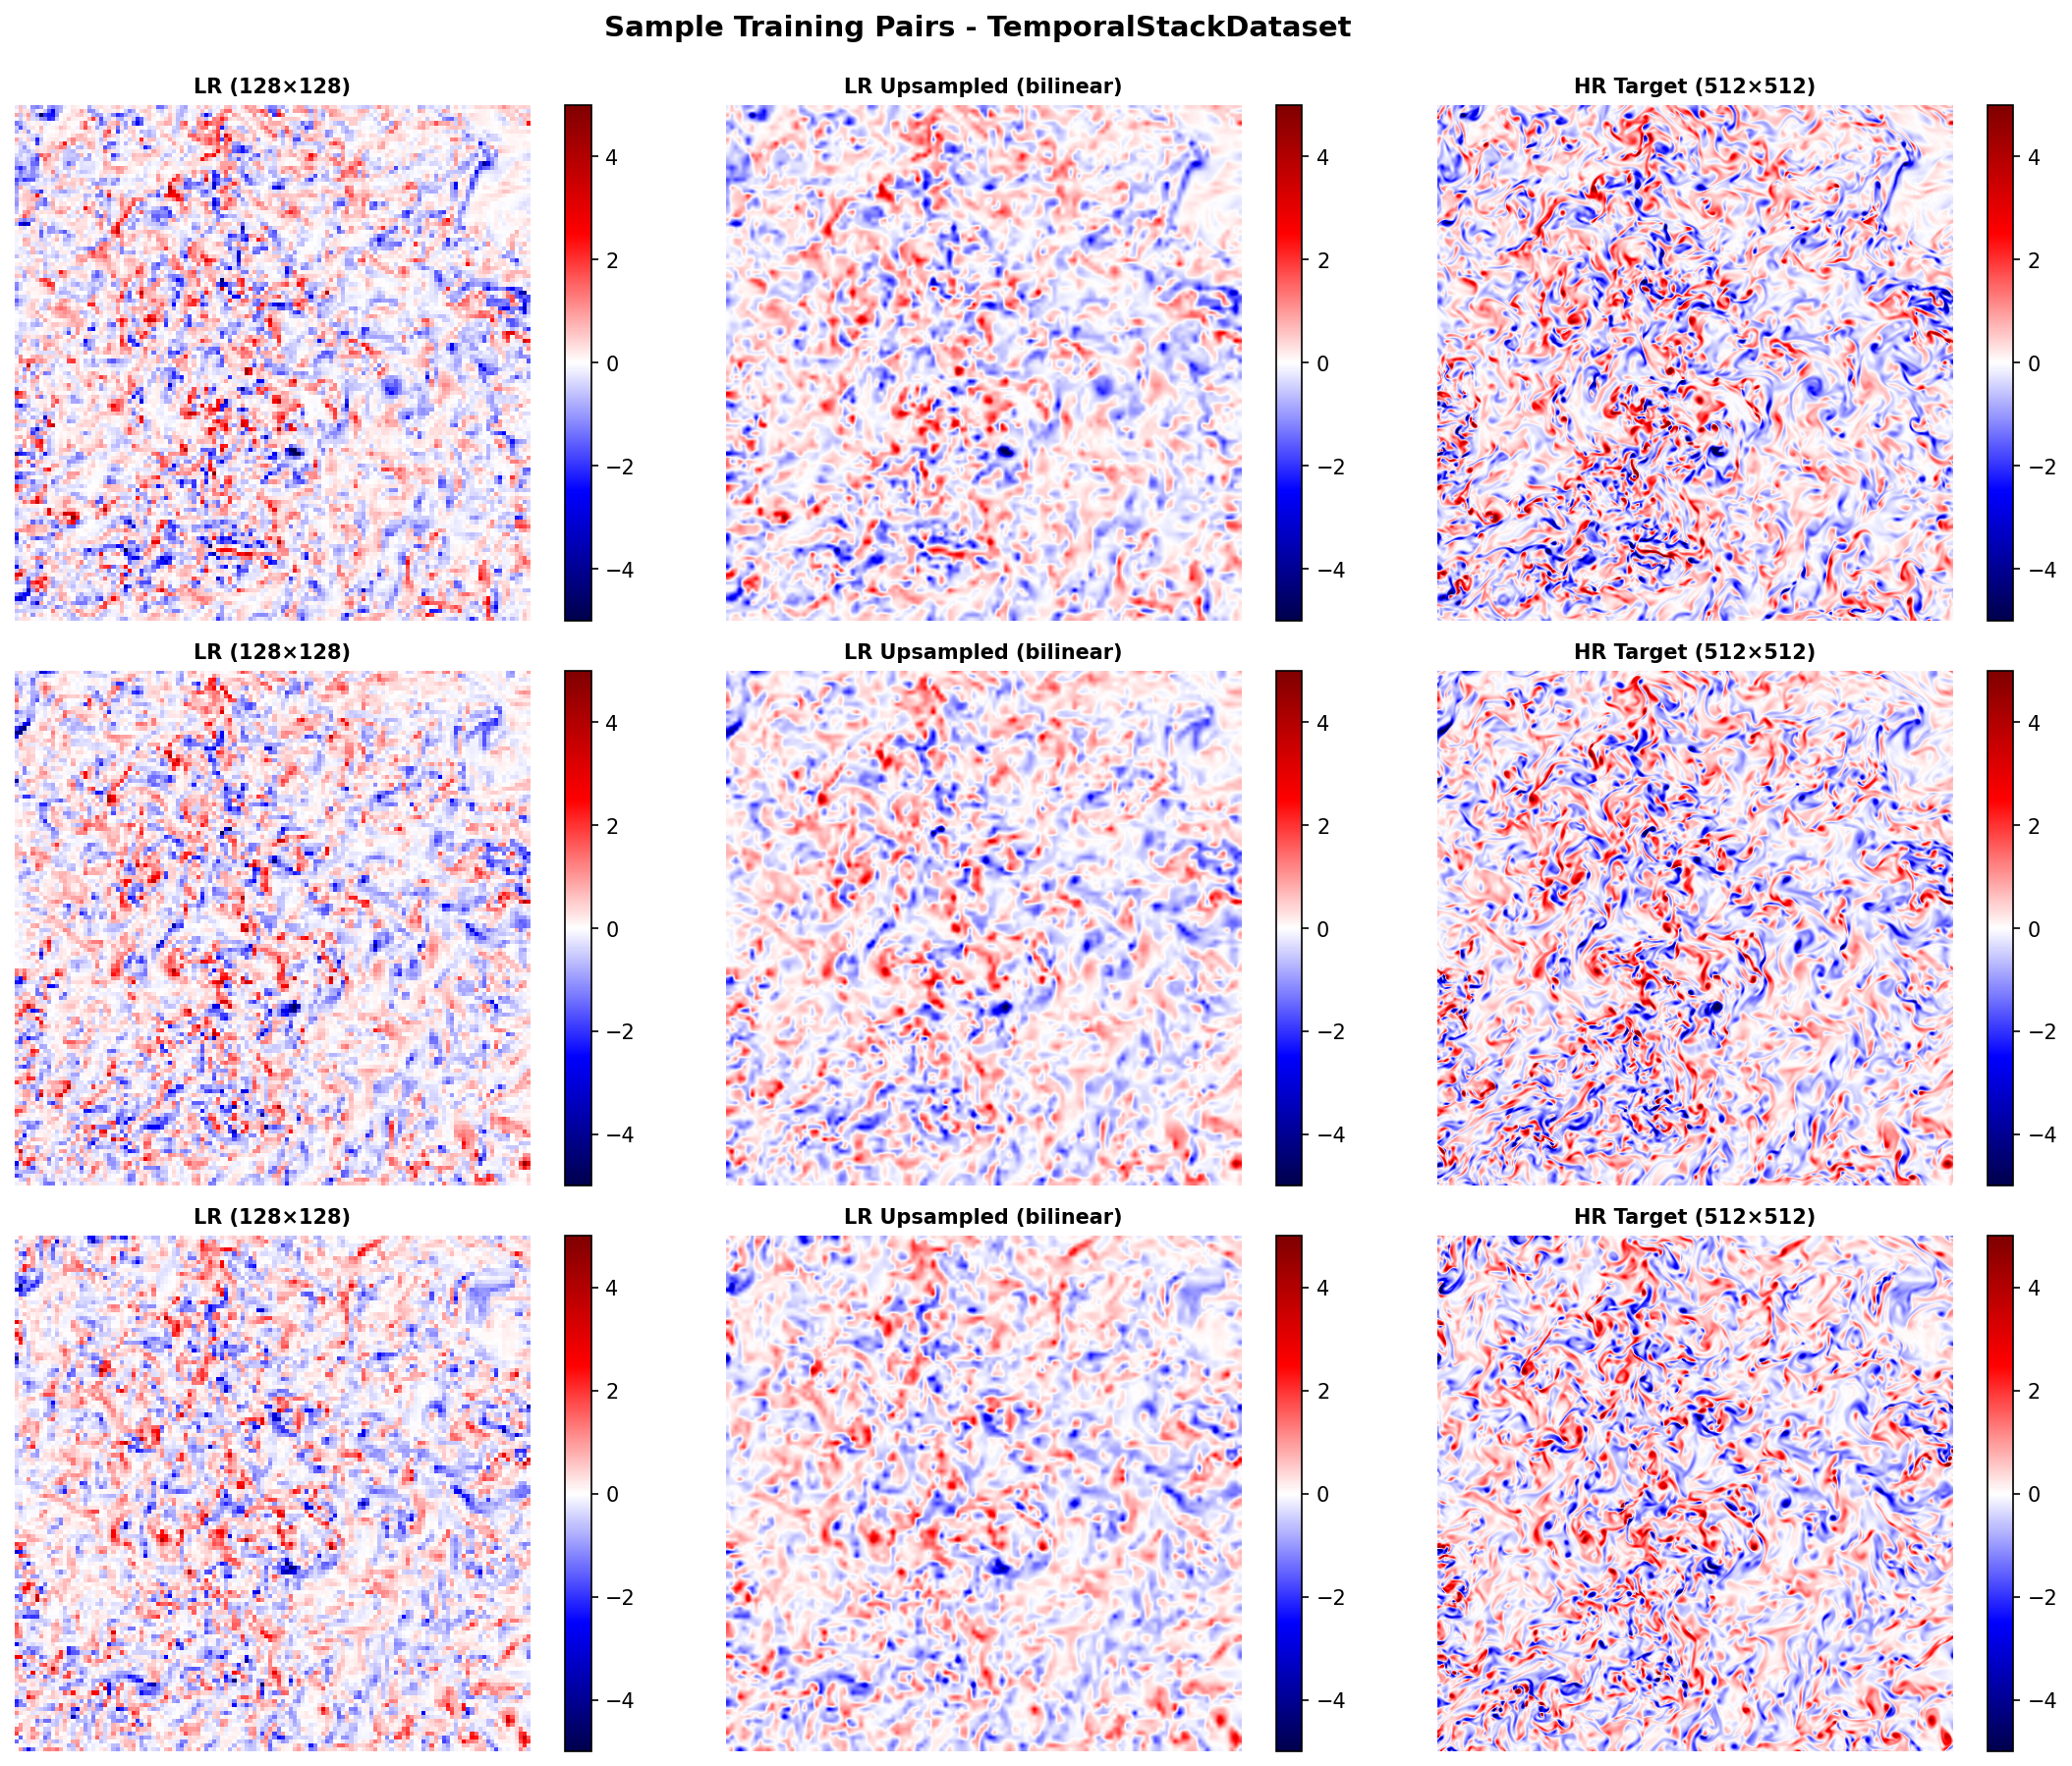

✓ Figure saved: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/work/SR/sr_edsr_isotropic_20251108_220719/plots/01_sample_lr_hr_pairs.png
  LR input shape: (1, 128, 128)
  HR target shape: (512, 512)
  Training pairs: 128×128 → 512×512
  Dataset type: TemporalStackDataset


In [6]:
# ...existing code...
# Visualize sample training pairs
n_samples = 3
fig, axes = plt.subplots(n_samples, 3, figsize=(15, 12))

# --------------------------------------"-------------------------------
# Colorbar limits: set CB_VMIN and CB_VMAX to desired values (or None to auto)
# ---------------------------------------------------------------------
# Examples:
#   CB_VMIN, CB_VMAX = -1.0, 1.0   # fixed symmetric range
#   CB_VMIN, CB_VMAX = 0.0, 2.0    # fixed positive range
#   CB_VMIN, CB_VMAX = None, None  # automatic (use HR sample min/max)
CB_VMIN, CB_VMAX = -5, 5

# determine fallback limits from a representative HR sample if available
if CB_VMIN is None or CB_VMAX is None:
    try:
        # hr_sample exists earlier in the notebook; use it if present
        _min = float(hr_sample.min())
        _max = float(hr_sample.max())
    except NameError:
        # fallback: will set per-sample limits later if needed
        _min, _max = None, None

# Use computed fallbacks to create final cb_vmin/cb_vmax (None stays None)
cb_vmin = CB_VMIN if CB_VMIN is not None else _min
cb_vmax = CB_VMAX if CB_VMAX is not None else _max
# ---------------------------------------------------------------------

for row in range(n_samples):
    # Get a sample from training set
    if USE_PHYSICS_DATASET:
        sample = train_dataset[row * 10]
        lr = sample['lr_omega']
        hr = sample['hr_omega']
    else:
        lr, hr = train_dataset[row * 10]
    
    # If temporal stacking, show only the last frame (current time)
    if lr.shape[0] > 1:
        lr_vis = lr[-1].numpy()  # Last frame
    else:
        lr_vis = lr[0].numpy()
    
    hr_vis = hr.numpy()
    
    # If per-sample fallback needed (no hr_sample available earlier), set here
    if cb_vmin is None or cb_vmax is None:
        sample_min = float(min(lr_vis.min(), hr_vis.min()))
        sample_max = float(max(lr_vis.max(), hr_vis.max()))
        _cb_vmin = cb_vmin if cb_vmin is not None else sample_min
        _cb_vmax = cb_vmax if cb_vmax is not None else sample_max
    else:
        _cb_vmin, _cb_vmax = cb_vmin, cb_vmax

    # Upsample LR for visualization
    lr_upsampled = F.interpolate(
        torch.from_numpy(lr_vis).unsqueeze(0).unsqueeze(0),
        size=(HR_SIZE, HR_SIZE),
        mode='bilinear',
        align_corners=False
    ).squeeze().numpy()
    
    CMAP = 'seismic'  # Colormap for visualization
    # Plot LR (use the same vmin/vmax for consistent colorbar scaling)
    im0 = axes[row, 0].imshow(lr_vis.T, cmap=CMAP, origin='lower', vmin=_cb_vmin, vmax=_cb_vmax)
    axes[row, 0].set_title(f'LR ({LR_SIZE}×{LR_SIZE})', fontsize=10, fontweight='bold')
    axes[row, 0].axis('off')
    plt.colorbar(im0, ax=axes[row, 0], fraction=0.046)
    
    # Plot LR upsampled
    im1 = axes[row, 1].imshow(lr_upsampled.T, cmap=CMAP, origin='lower', vmin=_cb_vmin, vmax=_cb_vmax)
    axes[row, 1].set_title('LR Upsampled (bilinear)', fontsize=10, fontweight='bold')
    axes[row, 1].axis('off')
    plt.colorbar(im1, ax=axes[row, 1], fraction=0.046)
    
    # Plot HR target
    im2 = axes[row, 2].imshow(hr_vis.T, cmap=CMAP, origin='lower', vmin=_cb_vmin, vmax=_cb_vmax)
    axes[row, 2].set_title(f'HR Target ({HR_SIZE}×{HR_SIZE})', fontsize=10, fontweight='bold')
    axes[row, 2].axis('off')
    plt.colorbar(im2, ax=axes[row, 2], fraction=0.046)

dataset_type = "MultiFieldDataset (physics-informed)" if USE_PHYSICS_DATASET else "TemporalStackDataset"
plt.suptitle(f'Sample Training Pairs - {dataset_type}', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_sample_lr_hr_pairs.png', bbox_inches='tight', dpi=150)
plt.show()
print(f"✓ Figure saved: {FIGURES_DIR / '01_sample_lr_hr_pairs.png'}")
print(f"  LR input shape: ({N_FRAMES}, {LR_SIZE}, {LR_SIZE})")
print(f"  HR target shape: ({HR_SIZE}, {HR_SIZE})")
print(f"  Training pairs: {LR_SIZE}×{LR_SIZE} → {HR_SIZE}×{HR_SIZE}")
print(f"  Dataset type: {dataset_type}")


# =============================================================================
# Physics Terms Visualization (Sample Data)
# =============================================================================
if USE_PHYSICS_DATASET:
    print("="*70)
    print("PHYSICS TERMS ANALYSIS (Sample Training Data)")
    print("="*70)

    # Get a sample with all fields
    sample = train_dataset[0]
    hr_ux_sample = sample['hr_ux'].numpy()
    hr_uy_sample = sample['hr_uy'].numpy()
    hr_omega_sample = sample['hr_omega'].numpy()

    # Compute advection term: u·∇ω
    def compute_advection_term(u, v, omega, dx, dy):
        u_t = torch.from_numpy(u).unsqueeze(0) if isinstance(u, np.ndarray) else u
        v_t = torch.from_numpy(v).unsqueeze(0) if isinstance(v, np.ndarray) else v
        omega_t = torch.from_numpy(omega).unsqueeze(0) if isinstance(omega, np.ndarray) else omega

        if u_t.dim() == 4:
            u_t, v_t, omega_t = u_t.squeeze(1), v_t.squeeze(1), omega_t.squeeze(1)

        domega_dx = (omega_t[:, :, 2:] - omega_t[:, :, :-2]) / (2 * dx)
        domega_dy = (omega_t[:, 2:, :] - omega_t[:, :-2, :]) / (2 * dy)

        u_c = u_t[:, 1:-1, 1:-1]
        v_c = v_t[:, 1:-1, 1:-1]
        domega_dx_c = domega_dx[:, 1:-1, :]
        domega_dy_c = domega_dy[:, :, 1:-1]

        result = u_c * domega_dx_c + v_c * domega_dy_c
        return result.squeeze(0).numpy() if hasattr(result, 'numpy') else result.squeeze(0)

    # Compute diffusion term: ∇²ω
    def compute_diffusion_term(omega, dx, dy):
        omega_t = torch.from_numpy(omega).unsqueeze(0) if isinstance(omega, np.ndarray) else omega

        if omega_t.dim() == 4:
            omega_t = omega_t.squeeze(1)

        d2omega_dx2 = (omega_t[:, :, 2:] - 2*omega_t[:, :, 1:-1] + omega_t[:, :, :-2]) / (dx**2)
        d2omega_dy2 = (omega_t[:, 2:, :] - 2*omega_t[:, 1:-1, :] + omega_t[:, :-2, :]) / (dy**2)

        d2omega_dx2_c = d2omega_dx2[:, 1:-1, :]
        d2omega_dy2_c = d2omega_dy2[:, :, 1:-1]

        result = d2omega_dx2_c + d2omega_dy2_c
        return result.squeeze(0).numpy() if hasattr(result, 'numpy') else result.squeeze(0)

    # Compute physics terms
    advection = compute_advection_term(hr_ux_sample, hr_uy_sample, hr_omega_sample, dx, dy)
    diffusion = compute_diffusion_term(hr_omega_sample, dx, dy)
    omega_cropped = hr_omega_sample[1:-1, 1:-1]

    print(f"\nField statistics (normalized):")
    print(f"  Vorticity ω:       [{hr_omega_sample.min():>10.3f}, {hr_omega_sample.max():>10.3f}], std={hr_omega_sample.std():.3f}")
    print(f"  Advection (u·∇ω):  [{advection.min():>10.3f}, {advection.max():>10.3f}], std={advection.std():.3f}")
    print(f"  Diffusion (∇²ω):   [{diffusion.min():>10.3f}, {diffusion.max():>10.3f}], std={diffusion.std():.3f}")

    # Estimate proper loss weights
    advection_mse = np.mean(advection ** 2)
    diffusion_mse = np.mean(diffusion ** 2)
    omega_mse = np.mean(omega_cropped ** 2)

    print(f"\n{'='*70}")
    print("PHYSICS LOSS SCALE ESTIMATE")
    print("="*70)
    print(f"Mean squared values:")
    print(f"  E(ω²):       {omega_mse:.2e}")
    print(f"  E((u·∇ω)²):  {advection_mse:.2e}")
    print(f"  E((∇²ω)²):   {diffusion_mse:.2e}")
    print(f"\nTo match vorticity loss scale, use:")
    print(f"  lambda_adv  ≈ {omega_mse / advection_mse:.2e}")
    print(f"  lambda_diff ≈ {omega_mse / diffusion_mse:.2e}")

    # Visualize
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # Row 1: Fields
    im0 = axes[0, 0].imshow(hr_omega_sample.T, cmap='seismic', origin='lower')
    axes[0, 0].set_title('Vorticity (ω)', fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')
    plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

    im1 = axes[0, 1].imshow(hr_ux_sample.T, cmap='seismic', origin='lower')
    axes[0, 1].set_title('Velocity u', fontsize=12, fontweight='bold')
    axes[0, 1].axis('off')
    plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

    im2 = axes[0, 2].imshow(hr_uy_sample.T, cmap='seismic', origin='lower')
    axes[0, 2].set_title('Velocity v', fontsize=12, fontweight='bold')
    axes[0, 2].axis('off')
    plt.colorbar(im2, ax=axes[0, 2], fraction=0.046)

    # Row 2: Physics terms (use percentile clipping for better visualization)
    adv_vmin, adv_vmax = np.percentile(advection, [1, 99])
    diff_vmin, diff_vmax = np.percentile(diffusion, [1, 99])

    im3 = axes[1, 0].imshow(omega_cropped.T, cmap='seismic', origin='lower')
    axes[1, 0].set_title('ω [cropped]', fontsize=12, fontweight='bold')
    axes[1, 0].axis('off')
    plt.colorbar(im3, ax=axes[1, 0], fraction=0.046)

    im4 = axes[1, 1].imshow(advection.T, cmap='RdBu_r', origin='lower',
                            vmin=adv_vmin, vmax=adv_vmax)
    axes[1, 1].set_title(f'Advection (u·∇ω)\nRange: [{adv_vmin:.1f}, {adv_vmax:.1f}]',
                          fontsize=12, fontweight='bold')
    axes[1, 1].axis('off')
    plt.colorbar(im4, ax=axes[1, 1], fraction=0.046)

    im5 = axes[1, 2].imshow(diffusion.T, cmap='RdBu_r', origin='lower',
                            vmin=diff_vmin, vmax=diff_vmax)
    axes[1, 2].set_title(f'Diffusion (∇²ω)\nRange: [{diff_vmin:.1f}, {diff_vmax:.1f}]',
                          fontsize=12, fontweight='bold')
    axes[1, 2].axis('off')
    plt.colorbar(im5, ax=axes[1, 2], fraction=0.046)

    plt.suptitle('Physics Terms for DNS (High-Resolution Ground Truth)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '01b_physics_terms_sample.png', bbox_inches='tight', dpi=150)
    plt.show()
    print(f"\n✓ Saved: {FIGURES_DIR / '01b_physics_terms_sample.png'}")

## Model Instantiation

Build model from configuration using the factory pattern.

In [7]:
# Show available architectures
print(f"Available architectures: {available_models()}")

# Update model config to account for temporal stacking
if N_FRAMES > 1:
    # Update in_ch for temporal stacking
    if 'unet' in config['model']:
        config['model']['unet']['in_ch'] = N_FRAMES
    if 'unet_turb' in config['model']:
        config['model']['unet_turb']['in_ch'] = N_FRAMES
    print(f"\nTemporal stacking enabled: input channels updated to {N_FRAMES}")

# Build model with correct LR/HR sizes
model = build_model_from_config(
    config['model'],
    patch_size_lr=LR_SIZE,   # 64
    patch_size_hr=HR_SIZE     # 256
)

# Device selection
DEVICE = torch.device('cpu')
if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')

model = model.to(DEVICE)
param_count = sum(p.numel() for p in model.parameters())

print(f"\n{'='*70}")
print(f"MODEL SUMMARY")
print(f"{'='*70}")
print(f"  Architecture: {config['model']['architecture']}")
print(f"  Class: {model.__class__.__name__}")
print(f"  Parameters: {param_count:,}")
print(f"  Device: {DEVICE}")
print(f"  Input: [{N_FRAMES}, {LR_SIZE}, {LR_SIZE}] → Output: [{HR_SIZE}, {HR_SIZE}]")
print(f"  Scale factor: {HR_SIZE // LR_SIZE}×")
print(f"{'='*70}")

Available architectures: ('edsr', 'hdsc_ms', 'mlp', 'unet')

MODEL SUMMARY
  Architecture: edsr
  Class: EDSR
  Parameters: 1,515,265
  Device: mps
  Input: [1, 128, 128] → Output: [512, 512]
  Scale factor: 4×


## Detailed Model Summary

Display layer-by-layer architecture and parameter counts.

In [8]:
# ============================================================================
# Detailed Model Summary
# ============================================================================
from torchinfo import summary

print(f"{'='*80}")
print(f"MODEL ARCHITECTURE SUMMARY")
print(f"{'='*80}\n")

# Use torchinfo for detailed summary
try:
    model_summary = summary(
        model,
        input_size=(1, N_FRAMES, LR_SIZE, LR_SIZE),
        col_names=['input_size', 'output_size', 'num_params', 'kernel_size'],
        depth=4,
        device=str(DEVICE),
        verbose=0
    )
    print(model_summary)
except ImportError:
    print("⚠️  Install torchinfo for detailed summary: pip install torchinfo\n")
    
    # Fallback: manual summary
    print(f"Architecture: {config['model']['architecture']}")
    print(f"Model class: {model.__class__.__name__}")
    print(f"Input shape: (batch, {N_FRAMES}, {LR_SIZE}, {LR_SIZE})")
    print(f"Output shape: (batch, 1, {HR_SIZE}, {HR_SIZE})")
    print(f"Scale factor: {HR_SIZE // LR_SIZE}×\n")
    
    print("\nLayer-by-layer breakdown:")
    print(f"{'Layer':<40} {'Parameters':>15}")
    print("-" * 56)
    
    total_params = 0
    for name, param in model.named_parameters():
        num_params = param.numel()
        total_params += num_params
        print(f"{name:<40} {num_params:>15,}")
    
    print("-" * 56)
    print(f"{'TOTAL PARAMETERS':<40} {total_params:>15,}")
    print(f"{'='*56}")
    
    # Memory estimate
    param_mb = total_params * 4 / (1024**2)  # 4 bytes per float32
    print(f"\nModel size (FP32): {param_mb:.2f} MB")
    print(f"Model size (FP16): {param_mb/2:.2f} MB")

print(f"\n{'='*80}")
print(f"KEY METRICS")
print(f"{'='*80}")
print(f"Total parameters: {param_count:,}")
print(f"Output resolution: {HR_SIZE}×{HR_SIZE} = {HR_SIZE**2:,} pixels")
print(f"Parameters per output pixel: {param_count / (HR_SIZE**2):.3f}")
print(f"\nRule of thumb for SR networks:")
print(f"  - Minimum: ~0.5 params/pixel (very lightweight)")
print(f"  - Good: 1-5 params/pixel (balanced)")
print(f"  - High capacity: 10+ params/pixel (complex textures)")
print(f"\nYour model: {param_count / (HR_SIZE**2):.3f} params/pixel → ", end="")
if param_count / (HR_SIZE**2) < 0.5:
    print("⚠️  May be too small!")
elif param_count / (HR_SIZE**2) < 5:
    print("✓ Good capacity")
else:
    print("✓ High capacity")
print(f"{'='*80}")


MODEL ARCHITECTURE SUMMARY

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
EDSR                                     [1, 1, 128, 128]          [1, 1, 512, 512]          --                        --
├─Conv2d: 1-1                            [1, 1, 128, 128]          [1, 64, 128, 128]         640                       [3, 3]
├─Sequential: 1-2                        [1, 64, 128, 128]         [1, 64, 128, 128]         --                        --
│    └─ResidualBlock: 2-1                [1, 64, 128, 128]         [1, 64, 128, 128]         --                        --
│    │    └─Sequential: 3-1              [1, 64, 128, 128]         [1, 64, 128, 128]         --                        --
│    │    │    └─Conv2d: 4-1             [1, 64, 128, 128]         [1, 64, 128, 128]         36,928                    [3, 3]
│    │    │    └─ReLU: 4-2               [1, 64, 128, 128]         [1, 64, 128, 128]         --     

## Training Setup

In [9]:
# Optimizer
train_cfg = config['training']
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=train_cfg['lr'],
    weight_decay=train_cfg.get('weight_decay', 0.0)
)

# Primary loss
loss_cfg = config['loss']['components']['pixel']
loss_type = 'smooth_l1' #loss_cfg.get('type', 'l2')
if loss_type == 'l1':
    pixel_loss = torch.nn.L1Loss()
elif loss_type == 'smooth_l1':
    pixel_loss = torch.nn.SmoothL1Loss()
else:
    pixel_loss = torch.nn.MSELoss()

# Auxiliary losses
GradLoss = GradientLoss().to(DEVICE) if config['loss']['components']['gradient']['enabled'] else None
SpecLoss = SpectralLoss().to(DEVICE) if config['loss']['components']['spectral']['enabled'] else None

# ============================================================================
# NEW: Physics-informed losses
# ============================================================================
USE_PHYSICS_LOSS = config['loss']['components'].get('physics', {}).get('enabled', False)
PhysicsLoss = None

if USE_PHYSICS_LOSS:
    physics_cfg = config['loss']['components']['physics']
    PhysicsLoss = PhysicsInformedLoss(
        lambda_adv=physics_cfg.get('lambda_adv', 0.01),
        lambda_diff=physics_cfg.get('lambda_diff', 0.01),
        lambda_grad=physics_cfg.get('lambda_grad', 0.0),
        reduction='mean'
    ).to(DEVICE)
    
    # Prepare velocity tensors (convert to torch, move to device later per batch)
    ux_hr_all = torch.from_numpy(all_fields['ux']).float()
    uy_hr_all = torch.from_numpy(all_fields['uy']).float()
    omega_hr_all = torch.from_numpy(all_fields['omega_z']).float()
    
    print(f"\n{'='*70}")
    
    # Extract normalization stats for physics loss
    sigma_ux = multifield_stats["ux"][1] if multifield_stats else 1.0
    sigma_uy = multifield_stats["uy"][1] if multifield_stats else 1.0
    sigma_omega = multifield_stats["omega_z"][1] if multifield_stats else 1.0
    
    print("PHYSICS-INFORMED TRAINING ENABLED")
    print(f"{'='*70}")
    print(f"  Advection loss weight (λ_adv):  {physics_cfg.get('lambda_adv', 0.01)}")
    print(f"  Diffusion loss weight (λ_diff): {physics_cfg.get('lambda_diff', 0.01)}")
    print(f"  Gradient reg. weight (λ_grad):  {physics_cfg.get('lambda_grad', 0.0)}")
    print(f"  Grid spacing: dx={dx:.6f}, dy={dy:.6f}")
    print(f"{'='*70}")

# Mixed precision
USE_MIXED_PRECISION = bool(train_cfg.get('mixed_precision', False))
if DEVICE.type == 'mps' and USE_MIXED_PRECISION:
    print("Mixed precision disabled on MPS to avoid stability issues.")
    USE_MIXED_PRECISION = False

# Gradient scaler for mixed precision
scaler = torch.amp.GradScaler('cuda', enabled=USE_MIXED_PRECISION and DEVICE.type == 'cuda')

print("\nTraining configuration:")
print(f"  Optimizer: AdamW (lr={train_cfg['lr']}, wd={train_cfg.get('weight_decay', 0.0)})")
print(f"  Primary loss: {loss_type.upper()}")
print(f"  Gradient loss: {'enabled' if GradLoss else 'disabled'}")
print(f"  Spectral loss: {'enabled' if SpecLoss else 'disabled'}")
print(f"  Physics loss: {'ENABLED' if USE_PHYSICS_LOSS else 'disabled'}")
print(f"  Mixed precision: {'enabled' if USE_MIXED_PRECISION else 'disabled'}")
print(f"  Gradient clipping: {train_cfg.get('gradient_clipping', {}).get('enabled', False)}")


Training configuration:
  Optimizer: AdamW (lr=0.0001, wd=0.0)
  Primary loss: SMOOTH_L1
  Gradient loss: disabled
  Spectral loss: disabled
  Physics loss: disabled
  Mixed precision: disabled
  Gradient clipping: True


## Training Loop

Train the model with progress tracking and validation.

In [10]:
EPOCHS = 100 #train_cfg['epochs']
history = {
    'train_loss': [], 'val_loss': [], 'val_psnr': [],
    'train_loss_pixel': [], 'train_loss_physics': [],
    'train_loss_advection': [], 'train_loss_diffusion': []
}
best_val = float('inf')

print(f"\nStarting training for {EPOCHS} epochs...\n")

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_epoch = 0.0
    train_loss_pixel_epoch = 0.0
    train_loss_physics_epoch = 0.0
    train_loss_adv_epoch = 0.0
    train_loss_diff_epoch = 0.0
    
    train_pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [train]', leave=False)
    
    for batch_idx, batch in enumerate(train_pbar):
        # Handle both dataset types
        if USE_PHYSICS_DATASET:
            lr_batch = batch['lr_omega'].to(DEVICE)
            hr_batch = batch['hr_omega'].unsqueeze(1).to(DEVICE)  # Add channel dim
            hr_ux = batch['hr_ux'].to(DEVICE)
            hr_uy = batch['hr_uy'].to(DEVICE)
        else:
            lr_batch, hr_batch = batch
            lr_batch = lr_batch.to(DEVICE)
            hr_batch = hr_batch.to(DEVICE)
            hr_batch = hr_batch.unsqueeze(1)  # Add channel dim: (B,H,W) → (B,1,H,W)

        optimizer.zero_grad(set_to_none=True)
        
        # Forward pass with optional mixed precision
        context = nullcontext()
        if USE_MIXED_PRECISION:
            if DEVICE.type == 'cuda':
                context = torch.cuda.amp.autocast()
            elif DEVICE.type == 'mps':
                context = torch.autocast(device_type='mps', dtype=torch.float16)

        with context:
            pred = model(lr_batch)
            
            # Primary pixel loss
            loss_pixel = pixel_loss(pred, hr_batch)
            loss = loss_pixel
            
            # Add auxiliary losses
            if GradLoss is not None:
                loss = loss + config['loss']['components']['gradient']['weight'] * GradLoss(pred, hr_batch)
            if SpecLoss is not None:
                loss = loss + config['loss']['components']['spectral']['weight'] * SpecLoss(pred, hr_batch)
            
            # ========================================================================
            # Physics-informed losses (only if using MultiFieldDataset)
            # ========================================================================
            loss_physics_total = torch.tensor(0.0, device=DEVICE)
            loss_adv = torch.tensor(0.0, device=DEVICE)
            loss_diff = torch.tensor(0.0, device=DEVICE)
            
            if USE_PHYSICS_LOSS and USE_PHYSICS_DATASET:
                # Compute physics losses on the HR target
                # We use the ground-truth velocity to compute physics consistency
                physics_losses = PhysicsLoss(
                    hr_ux,                    # u_pred (DNS velocity)
                    hr_uy,                    # v_pred (DNS velocity)  
                    pred.squeeze(1),          # omega_pred (ML vorticity) ← KEY: uses predicted!
                    hr_ux,                    # u_target (DNS velocity)
                    hr_uy,                    # v_target (DNS velocity)
                    hr_batch.squeeze(1),      # omega_target (DNS vorticity)
                    dx, dy,
                    sigma_ux=sigma_ux, sigma_uy=sigma_uy, sigma_omega=sigma_omega
                )
                
                loss_physics_total = physics_losses['total']
                loss_adv = physics_losses['advection']
                loss_diff = physics_losses['diffusion']
                
                # Add physics loss to total loss
                loss = loss + loss_physics_total

        # Backward pass
        if USE_MIXED_PRECISION and DEVICE.type == 'cuda':
            scaler.scale(loss).backward()
            if train_cfg.get('gradient_clipping', {}).get('enabled', False):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), train_cfg['gradient_clipping']['max_norm'])
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if train_cfg.get('gradient_clipping', {}).get('enabled', False):
                torch.nn.utils.clip_grad_norm_(model.parameters(), train_cfg['gradient_clipping']['max_norm'])
            optimizer.step()

        train_loss_epoch += loss.item()
        train_loss_pixel_epoch += loss_pixel.item()
        train_loss_physics_epoch += loss_physics_total.item()
        train_loss_adv_epoch += loss_adv.item()
        train_loss_diff_epoch += loss_diff.item()
        
        train_pbar.set_postfix(
            loss=f"{loss.item():.4f}",
            pix=f"{loss_pixel.item():.4f}",
            phy=f"{loss_physics_total.item():.4f}" if USE_PHYSICS_LOSS and USE_PHYSICS_DATASET else "off"
        )

    train_loss_epoch /= len(train_loader)
    train_loss_pixel_epoch /= len(train_loader)
    train_loss_physics_epoch /= len(train_loader)
    train_loss_adv_epoch /= len(train_loader)
    train_loss_diff_epoch /= len(train_loader)
    
    history['train_loss'].append(train_loss_epoch)
    history['train_loss_pixel'].append(train_loss_pixel_epoch)
    history['train_loss_physics'].append(train_loss_physics_epoch)
    history['train_loss_advection'].append(train_loss_adv_epoch)
    history['train_loss_diffusion'].append(train_loss_diff_epoch)

    # Validation
    model.eval()
    val_loss_epoch = 0.0
    val_psnr_epoch = 0.0
    val_pbar = tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [val]', leave=False)
    
    with torch.no_grad():
        for batch in val_pbar:
            # Handle both dataset types
            if USE_PHYSICS_DATASET:
                lr_batch = batch['lr_omega'].to(DEVICE)
                hr_batch = batch['hr_omega'].unsqueeze(1).to(DEVICE)
            else:
                lr_batch, hr_batch = batch
                lr_batch = lr_batch.to(DEVICE)
                hr_batch = hr_batch.to(DEVICE)
                hr_batch = hr_batch.unsqueeze(1)  # Add channel dim: (B,H,W) → (B,1,H,W)
            
            context = nullcontext()
            if USE_MIXED_PRECISION:
                if DEVICE.type == 'cuda':
                    context = torch.cuda.amp.autocast()
                elif DEVICE.type == 'mps':
                    context = torch.autocast(device_type='mps', dtype=torch.float16)
            
            with context:
                pred = model(lr_batch)
                loss = pixel_loss(pred, hr_batch)
                if GradLoss is not None:
                    loss = loss + config['loss']['components']['gradient']['weight'] * GradLoss(pred, hr_batch)
                if SpecLoss is not None:
                    loss = loss + config['loss']['components']['spectral']['weight'] * SpecLoss(pred, hr_batch)
            
            val_loss_epoch += loss.item()
            val_psnr_epoch += psnr(pred, hr_batch).item()
            val_pbar.set_postfix(loss=f"{loss.item():.4f}")
    
    val_loss_epoch /= len(val_loader)
    val_psnr_epoch /= len(val_loader)
    history['val_loss'].append(val_loss_epoch)
    history['val_psnr'].append(val_psnr_epoch)

    # Print epoch summary
    if USE_PHYSICS_LOSS and USE_PHYSICS_DATASET:
        print(f"Epoch {epoch+1:03d}: train={train_loss_epoch:.4f} (pix={train_loss_pixel_epoch:.4f}, phy={train_loss_physics_epoch:.4f}, adv={train_loss_adv_epoch:.4f}, diff={train_loss_diff_epoch:.4f}) | val={val_loss_epoch:.4f} | PSNR={val_psnr_epoch:.2f} dB")
    else:
        print(f"Epoch {epoch+1:03d}: train={train_loss_epoch:.4f} | val={val_loss_epoch:.4f} | PSNR={val_psnr_epoch:.2f} dB")
    
    # Save best model
    if val_loss_epoch < best_val:
        best_val = val_loss_epoch
        torch.save(model.state_dict(), manager.checkpoints_dir / 'best_model.pth')

manager.save_history(history)
print(f"\nTraining complete! Best validation loss: {best_val:.4f}")

if USE_PHYSICS_LOSS and USE_PHYSICS_DATASET:
    print(f"\nPhysics-informed training completed successfully!")
    print(f"  Final advection loss: {train_loss_adv_epoch:.6f}")
    print(f"  Final diffusion loss: {train_loss_diff_epoch:.6f}")


Starting training for 100 epochs...



Epoch 1/100 [train]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/100 [val]:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 001: train=0.0852 | val=0.1402 | PSNR=30.07 dB


Epoch 2/100 [train]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 2/100 [val]:   0%|          | 0/10 [00:00<?, ?it/s]

... (53 outputs left out)

Epoch 20/100 [val]:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 020: train=0.0665 | val=0.1210 | PSNR=30.74 dB


Epoch 21/100 [train]:   0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

## Training History Visualization

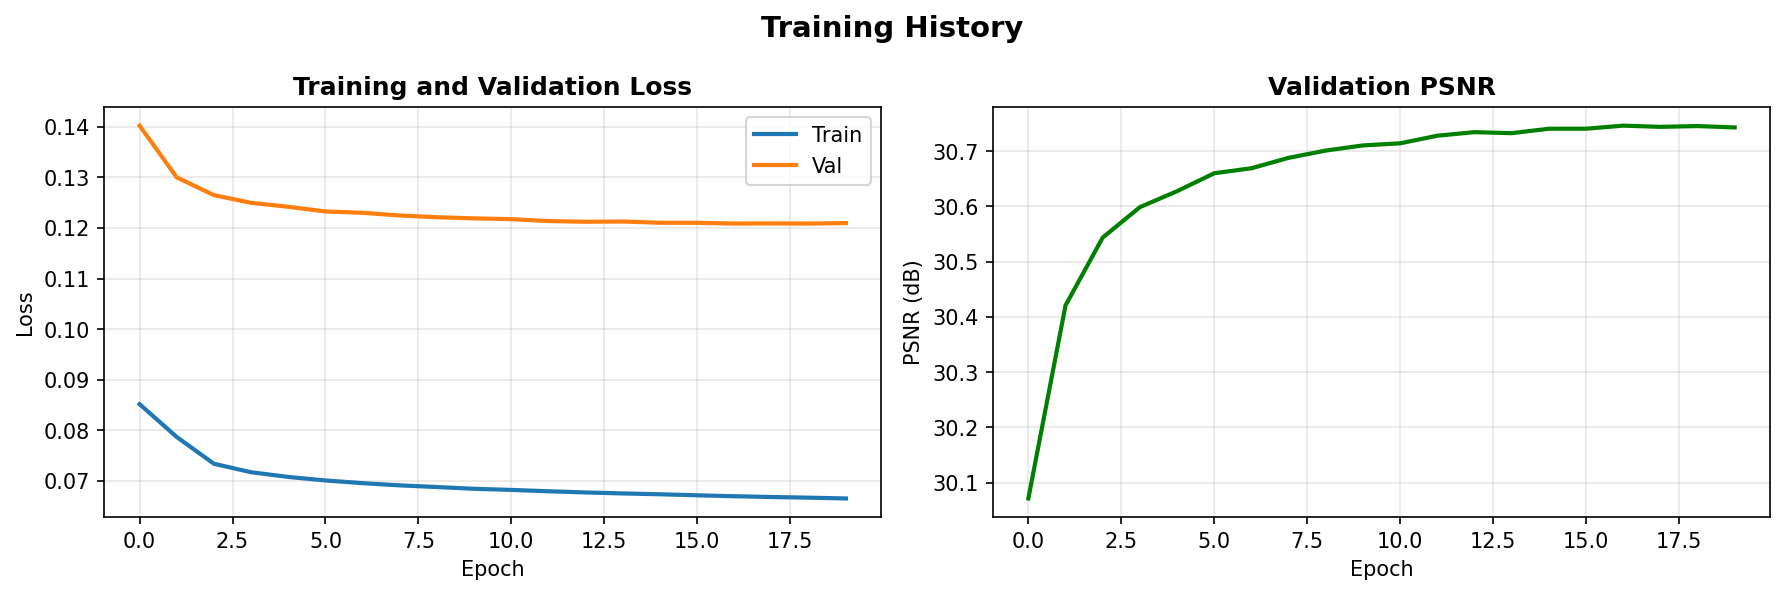

Figure saved: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/work/SR/sr_edsr_isotropic_20251108_220719/plots/03_training_history.png


In [11]:
if USE_PHYSICS_LOSS and USE_PHYSICS_DATASET:
    # Extended visualization with physics losses
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Total loss
    axes[0, 0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0, 0].plot(history['val_loss'], label='Val', linewidth=2)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].set_title('Total Loss', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)
    
    # Loss components
    axes[0, 1].plot(history['train_loss_pixel'], label='Pixel', linewidth=2, color='blue')
    axes[0, 1].plot(history['train_loss_physics'], label='Physics', linewidth=2, color='red')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].set_title('Loss Components (Train)', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)
    
    # Physics loss breakdown
    axes[1, 0].plot(history['train_loss_advection'], label='Advection', linewidth=2, color='orange')
    axes[1, 0].plot(history['train_loss_diffusion'], label='Diffusion', linewidth=2, color='green')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].set_title('Physics Loss Breakdown', fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)
    
    # Validation PSNR
    axes[1, 1].plot(history['val_psnr'], linewidth=2, color='green')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('PSNR (dB)')
    axes[1, 1].set_title('Validation PSNR', fontweight='bold')
    axes[1, 1].grid(alpha=0.3)
    
    plt.suptitle('Training History (Physics-Informed)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '03_training_history.png', bbox_inches='tight', dpi=150)
    plt.show()
    
else:
    # Standard visualization
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0].plot(history['val_loss'], label='Val', linewidth=2)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss', fontweight='bold')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history['val_psnr'], linewidth=2, color='green')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('PSNR (dB)')
    axes[1].set_title('Validation PSNR', fontweight='bold')
    axes[1].grid(alpha=0.3)

    plt.suptitle('Training History', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '03_training_history.png', bbox_inches='tight', dpi=150)
    plt.show()

print(f"Figure saved: {FIGURES_DIR / '03_training_history.png'}")

## Model Evaluation

In [12]:
# Load best model
model.load_state_dict(torch.load(manager.checkpoints_dir / 'best_model.pth', map_location=DEVICE, weights_only=True))
model.eval()

# Get a validation sample
if USE_PHYSICS_DATASET:
    sample = val_dataset[0]
    val_lr = sample['lr_omega']
    val_hr = sample['hr_omega']
else:
    val_lr, val_hr = val_dataset[0]

# Predict
with torch.no_grad():
    sr_patch = model(val_lr.unsqueeze(0).to(DEVICE)).squeeze(0).squeeze(0).cpu()

    # Also generate bicubic baseline
    lr_for_bicubic = val_lr if val_lr.dim() == 3 else val_lr.unsqueeze(0)
    bicubic_patch = F.interpolate(
        lr_for_bicubic.unsqueeze(0),
        size=(HR_SIZE, HR_SIZE),
        mode='bicubic',
        align_corners=False
    ).squeeze(0).squeeze(0).cpu()

# Convert to numpy
lr_np = val_lr[-1].numpy() if val_lr.dim() == 3 else val_lr[0].numpy()
hr_np = val_hr.numpy()
sr_np = sr_patch.numpy()
bicubic_np = bicubic_patch.numpy()

# Compute metrics
mae_sr = np.mean(np.abs(sr_np - hr_np))
mae_bicubic = np.mean(np.abs(bicubic_np - hr_np))
psnr_sr = psnr(torch.from_numpy(sr_np).unsqueeze(0).unsqueeze(0),
               torch.from_numpy(hr_np).unsqueeze(0).unsqueeze(0)).item()
psnr_bicubic = psnr(torch.from_numpy(bicubic_np).unsqueeze(0).unsqueeze(0),
                    torch.from_numpy(hr_np).unsqueeze(0).unsqueeze(0)).item()

print("="*70)
print("VALIDATION SAMPLE METRICS")
print("="*70)
print(f"\nData ranges (normalized):")
print(f"  LR input:    [{lr_np.min():>7.3f}, {lr_np.max():>7.3f}]")
print(f"  Bicubic:     [{bicubic_np.min():>7.3f}, {bicubic_np.max():>7.3f}]")
print(f"  SR (ours):   [{sr_np.min():>7.3f}, {sr_np.max():>7.3f}]")
print(f"  HR target:   [{hr_np.min():>7.3f}, {hr_np.max():>7.3f}]")
print(f"\nMetrics:")
print(f"  Bicubic:     MAE={mae_bicubic:.4f}, PSNR={psnr_bicubic:.2f} dB")
print(f"  SR (ours):   MAE={mae_sr:.4f}, PSNR={psnr_sr:.2f} dB")
print(f"  Improvement: {psnr_sr - psnr_bicubic:+.2f} dB")
print("="*70)

# Visualize: SEPARATE LARGE FIGURES
data_dict = {
    '01_LR_input': (lr_np, f'LR Input ({LR_SIZE}×{LR_SIZE})'),
    '02_bicubic': (bicubic_np, f'Bicubic Upsampling\\nMAE={mae_bicubic:.4f}, PSNR={psnr_bicubic:.2f} dB'),
    '03_sr_ours': (sr_np, f'SR Model (ours)\\nMAE={mae_sr:.4f}, PSNR={psnr_sr:.2f} dB'),
    '04_hr_target': (hr_np, f'HR Ground Truth ({HR_SIZE}×{HR_SIZE})')
}

# Use common colorbar limits
vmin = min(d[0].min() for d in data_dict.values())
vmax = max(d[0].max() for d in data_dict.values())

for filename, (field, title) in data_dict.items():
    fig = plt.figure(figsize=(12, 10))
    im = plt.imshow(field.T, cmap='seismic', origin='lower', vmin=vmin, vmax=vmax)
    plt.title(title, fontsize=16, fontweight='bold', pad=20)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.axis('off')
    plt.tight_layout()
    save_path = FIGURES_DIR / f'{filename}.png'
    plt.savefig(save_path, bbox_inches='tight', dpi=200)
    plt.close()
    print(f"✓ Saved: {save_path.name}")

print(f"\n✓ All figures saved to: {FIGURES_DIR}")
print(f"  View them individually to see fine-scale structures!")

# =============================================================================
# Physics Terms Comparison (DNS vs ML vs Bicubic) - EXTENDED VISUALIZATION
# =============================================================================

# First, compute and show standard metrics (keep your existing code)
print("="*70)
print("VALIDATION SAMPLE METRICS")
print("="*70)
print(f"\nData ranges (normalized):")
print(f"  LR input:    [{lr_np.min():>7.3f}, {lr_np.max():>7.3f}]")
print(f"  Bicubic:     [{bicubic_np.min():>7.3f}, {bicubic_np.max():>7.3f}]")
print(f"  SR (ours):   [{sr_np.min():>7.3f}, {sr_np.max():>7.3f}]")
print(f"  HR target:   [{hr_np.min():>7.3f}, {hr_np.max():>7.3f}]")
print(f"\nMetrics:")
print(f"  Bicubic:     MAE={mae_bicubic:.4f}, PSNR={psnr_bicubic:.2f} dB")
print(f"  SR (ours):   MAE={mae_sr:.4f}, PSNR={psnr_sr:.2f} dB")
print(f"  Improvement: {psnr_sr - psnr_bicubic:+.2f} dB")
print("="*70)

# Visualize standard fields
data_dict = {
    '01_LR_input': (lr_np, f'LR Input ({LR_SIZE}×{LR_SIZE})'),
    '02_bicubic': (bicubic_np, f'Bicubic\nMAE={mae_bicubic:.4f}, PSNR={psnr_bicubic:.2f} dB'),
    '03_sr_ours': (sr_np, f'SR (ours)\nMAE={mae_sr:.4f}, PSNR={psnr_sr:.2f} dB'),
    '04_hr_target': (hr_np, f'HR Ground Truth ({HR_SIZE}×{HR_SIZE})')
}

vmin = min(d[0].min() for d in data_dict.values())
vmax = max(d[0].max() for d in data_dict.values())

for filename, (field, title) in data_dict.items():
    fig = plt.figure(figsize=(12, 10))
    im = plt.imshow(field.T, cmap='seismic', origin='lower', vmin=vmin, vmax=vmax)
    plt.title(title, fontsize=16, fontweight='bold', pad=20)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.axis('off')
    plt.tight_layout()
    save_path = FIGURES_DIR / f'{filename}.png'
    plt.savefig(save_path, bbox_inches='tight', dpi=200)
    plt.close()
    print(f"✓ Saved: {save_path.name}")

# NOW ADD PHYSICS COMPARISON (if physics dataset was used)
if USE_PHYSICS_DATASET:
    print(f"\n{'='*70}")
    print("PHYSICS TERMS COMPARISON")
    print("="*70)

    # Get velocity fields
    sample_full = val_dataset[0]
    hr_ux_np = sample_full['hr_ux'].numpy()
    hr_uy_np = sample_full['hr_uy'].numpy()

    # Use the functions defined earlier (or redefine them here)
    def compute_advection_term(u, v, omega, dx, dy):
        u_t = torch.from_numpy(u).unsqueeze(0) if isinstance(u, np.ndarray) else u
        v_t = torch.from_numpy(v).unsqueeze(0) if isinstance(v, np.ndarray) else v
        omega_t = torch.from_numpy(omega).unsqueeze(0) if isinstance(omega, np.ndarray) else omega

        if u_t.dim() == 4:
            u_t, v_t, omega_t = u_t.squeeze(1), v_t.squeeze(1), omega_t.squeeze(1)

        domega_dx = (omega_t[:, :, 2:] - omega_t[:, :, :-2]) / (2 * dx)
        domega_dy = (omega_t[:, 2:, :] - omega_t[:, :-2, :]) / (2 * dy)
        u_c = u_t[:, 1:-1, 1:-1]
        v_c = v_t[:, 1:-1, 1:-1]
        domega_dx_c = domega_dx[:, 1:-1, :]
        domega_dy_c = domega_dy[:, :, 1:-1]

        result = u_c * domega_dx_c + v_c * domega_dy_c
        return result.squeeze(0).numpy() if hasattr(result, 'numpy') else result.squeeze(0)

    def compute_diffusion_term(omega, dx, dy):
        omega_t = torch.from_numpy(omega).unsqueeze(0) if isinstance(omega, np.ndarray) else omega
        if omega_t.dim() == 4:
            omega_t = omega_t.squeeze(1)

        d2omega_dx2 = (omega_t[:, :, 2:] - 2*omega_t[:, :, 1:-1] + omega_t[:, :, :-2]) / (dx**2)
        d2omega_dy2 = (omega_t[:, 2:, :] - 2*omega_t[:, 1:-1, :] + omega_t[:, :-2, :]) / (dy**2)
        d2omega_dx2_c = d2omega_dx2[:, 1:-1, :]
        d2omega_dy2_c = d2omega_dy2[:, :, 1:-1]

        result = d2omega_dx2_c + d2omega_dy2_c
        return result.squeeze(0).numpy() if hasattr(result, 'numpy') else result.squeeze(0)

    # Compute physics terms for all methods
    adv_dns = compute_advection_term(hr_ux_np, hr_uy_np, hr_np, dx, dy)
    diff_dns = compute_diffusion_term(hr_np, dx, dy)

    adv_ml = compute_advection_term(hr_ux_np, hr_uy_np, sr_np, dx, dy)
    diff_ml = compute_diffusion_term(sr_np, dx, dy)

    adv_bicubic = compute_advection_term(hr_ux_np, hr_uy_np, bicubic_np, dx, dy)
    diff_bicubic = compute_diffusion_term(bicubic_np, dx, dy)

    # Compute errors
    adv_error_ml = np.abs(adv_ml - adv_dns)
    diff_error_ml = np.abs(diff_ml - diff_dns)
    adv_error_bicubic = np.abs(adv_bicubic - adv_dns)
    diff_error_bicubic = np.abs(diff_bicubic - diff_dns)

    print(f"Advection (u·∇ω) MAE:")
    print(f"  ML:      {np.mean(adv_error_ml):.6f}")
    print(f"  Bicubic: {np.mean(adv_error_bicubic):.6f}")
    print(f"  Improvement: {(1 - np.mean(adv_error_ml)/np.mean(adv_error_bicubic))*100:.1f}%")

    print(f"\nDiffusion (∇²ω) MAE:")
    print(f"  ML:      {np.mean(diff_error_ml):.6f}")
    print(f"  Bicubic: {np.mean(diff_error_bicubic):.6f}")
    print(f"  Improvement: {(1 - np.mean(diff_error_ml)/np.mean(diff_error_bicubic))*100:.1f}%")

    # Create comparison figure
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 4, hspace=0.3, wspace=0.3)

    # Use percentile clipping
    adv_vmin, adv_vmax = np.percentile(adv_dns, [1, 99])
    diff_vmin, diff_vmax = np.percentile(diff_dns, [1, 99])

    # Row 1: Advection
    ax = fig.add_subplot(gs[0, 0])
    im = ax.imshow(adv_dns.T, cmap='RdBu_r', origin='lower', vmin=adv_vmin, vmax=adv_vmax)
    ax.set_title('Advection\n(DNS)', fontsize=10, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[0, 1])
    im = ax.imshow(adv_bicubic.T, cmap='RdBu_r', origin='lower', vmin=adv_vmin, vmax=adv_vmax)
    ax.set_title('Advection\n(Bicubic)', fontsize=10, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[0, 2])
    im = ax.imshow(adv_ml.T, cmap='RdBu_r', origin='lower', vmin=adv_vmin, vmax=adv_vmax)
    ax.set_title('Advection\n(ML)', fontsize=10, fontweight='bold', color='blue')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[0, 3])
    err_max = max(np.percentile(adv_error_ml, 99), np.percentile(adv_error_bicubic, 99))
    im = ax.imshow(adv_error_ml.T, cmap='hot', origin='lower', vmin=0, vmax=err_max)
    ax.set_title(f'|Error| ML\nMAE={np.mean(adv_error_ml):.4f}', fontsize=10, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    # Row 2: Diffusion
    ax = fig.add_subplot(gs[1, 0])
    im = ax.imshow(diff_dns.T, cmap='RdBu_r', origin='lower', vmin=diff_vmin, vmax=diff_vmax)
    ax.set_title('Diffusion\n(DNS)', fontsize=10, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[1, 1])
    im = ax.imshow(diff_bicubic.T, cmap='RdBu_r', origin='lower', vmin=diff_vmin, vmax=diff_vmax)
    ax.set_title('Diffusion\n(Bicubic)', fontsize=10, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[1, 2])
    im = ax.imshow(diff_ml.T, cmap='RdBu_r', origin='lower', vmin=diff_vmin, vmax=diff_vmax)
    ax.set_title('Diffusion\n(ML)', fontsize=10, fontweight='bold', color='blue')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[1, 3])
    err_max = max(np.percentile(diff_error_ml, 99), np.percentile(diff_error_bicubic, 99))
    im = ax.imshow(diff_error_ml.T, cmap='hot', origin='lower', vmin=0, vmax=err_max)
    ax.set_title(f'|Error| ML\nMAE={np.mean(diff_error_ml):.4f}', fontsize=10, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

    plt.suptitle('Physics Terms: DNS vs ML vs Bicubic', fontsize=14, fontweight='bold')
    plt.savefig(FIGURES_DIR / '05_physics_comparison.png', bbox_inches='tight', dpi=150)
    plt.show()
    print(f"\n✓ Saved: {FIGURES_DIR / '05_physics_comparison.png'}")

VALIDATION SAMPLE METRICS

Data ranges (normalized):
  LR input:    [ -7.774,   8.348]
  Bicubic:     [ -7.661,   8.949]
  SR (ours):   [-11.646,  12.526]
  HR target:   [-14.611,  16.514]

Metrics:
  Bicubic:     MAE=0.3867, PSNR=28.41 dB
  SR (ours):   MAE=0.3291, PSNR=29.62 dB
  Improvement: +1.21 dB
✓ Saved: 01_LR_input.png
✓ Saved: 02_bicubic.png
✓ Saved: 03_sr_ours.png
✓ Saved: 04_hr_target.png

✓ All figures saved to: /Users/pranithaditya/Desktop/postdoc IST/research_and_learning/jhtdb-ml/work/SR/sr_edsr_isotropic_20251108_220719/plots
  View them individually to see fine-scale structures!
VALIDATION SAMPLE METRICS

Data ranges (normalized):
  LR input:    [ -7.774,   8.348]
  Bicubic:     [ -7.661,   8.949]
  SR (ours):   [-11.646,  12.526]
  HR target:   [-14.611,  16.514]

Metrics:
  Bicubic:     MAE=0.3867, PSNR=28.41 dB
  SR (ours):   MAE=0.3291, PSNR=29.62 dB
  Improvement: +1.21 dB
✓ Saved: 01_LR_input.png
✓ Saved: 02_bicubic.png
✓ Saved: 03_sr_ours.png
✓ Saved: 04_hr_tar

## Save Model and Metadata

In [ ]:
# Save to saved_models directory
MODEL_SAVE_DIR = ROOT / 'saved_models/SR'
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
model_name = f"{config['model']['architecture']}_x{config['model']['scale_factor']}_{timestamp}"
model_path = MODEL_SAVE_DIR / f"{model_name}.pth"

# Save model state dict
torch.save(model.state_dict(), model_path)

# Create comprehensive metadata
metadata = {
    'model_name': model_name,
    'architecture': config['model']['architecture'],
    'scale_factor': config['model']['scale_factor'],
    'component': component,
    'input_size': [N_FRAMES, LR_SIZE, LR_SIZE],
    'output_size': [HR_SIZE, HR_SIZE],
    'parameters': int(param_count),
    'epochs': int(config['training']['epochs']),
    'best_val_loss': float(min(history['val_loss'])),
    'best_val_psnr': float(max(history['val_psnr'])),
    'fullfield_mae': float(mae_full),
    'fullfield_psnr': float(psnr_full),
    'experiment_dir': str(manager.run_dir),
    'dataset': str(h5_path),
    'config_file': str(CONFIG_PATH),
    'data_split': {
        'train_snapshots': len(train_idx),
        'val_snapshots': len(val_idx),
        'test_snapshots': len(test_idx),
        'split_method': 'snapshot-wise (temporal order preserved)'
    },
    'temporal_stacking': {
        'enabled': config['data']['temporal']['enabled'],
        'num_frames': N_FRAMES
    },
    'augmentation': {
        'enabled': config['data']['augmentation']['enabled'],
        'methods': list(config['data']['augmentation'].keys()) if config['data']['augmentation']['enabled'] else []
    },
    'normalization': config['data']['normalization']['method']
}

metadata_path = MODEL_SAVE_DIR / f"{model_name}_metadata.json"
with open(metadata_path, 'w') as fp:
    json.dump(metadata, fp, indent=2)

print(f"\n{'='*70}")
print(f"MODEL SAVED")
print(f"{'='*70}")
print(f"  Weights: {model_path}")
print(f"  Metadata: {metadata_path}")
print(f"\nModel can be loaded with:")
print(f"  from models.factory import build_model_from_config")
print(f"  model = build_model_from_config(config['model'], {LR_SIZE}, {HR_SIZE})")
print(f"  model.load_state_dict(torch.load('{model_path}'))")
print(f"{'='*70}")

## Summary

In [ ]:
print("="*70)
print("SUPER-RESOLUTION PIPELINE SUMMARY")
print("="*70)
print(f"Dataset:              {h5_path.name}")
print(f"Component:            {component}")
print(f"Snapshots:            {hr_data.shape[0]}")
print(f"Architecture:         {config['model']['architecture']}")
print(f"Scale factor:         {DOWNSCALE_FACTOR}×")
print(f"Parameters:           {param_count:,}")
print(f"Training epochs:      {EPOCHS}")
print(f"Best val PSNR:        {max(history['val_psnr']):.2f} dB")
print(f"Full-field MAE:       {mae_full:.4f}")
print(f"Full-field PSNR:      {psnr_full:.2f} dB")
print(f"\nArtifacts:")
print(f"  Experiment dir:     {manager.run_dir}")
print(f"  Model saved:        {model_path}")
print(f"  Figures:            {len(list(FIGURES_DIR.glob('*.png')))} plots")
print("="*70)